# Part A: LEAD 1.0 labels, join, and events (version 2)

What this notebook does:
1. Opens the LEAD 1.0 file and shows what is in it.
2. Keeps only the buildings that LEAD labels. Buildings outside the file have no labels, so they cannot be treated as normal.
3. Puts GEPIII readings in the same unit as LEAD (site 0 is stored in kBTU in GEPIII and in kWh in LEAD).
4. Checks that LEAD's readings match GEPIII's, and explains the rows that do not.
5. Marks long runs of zero readings.
6. Turns labeled hours into events and sorts them into length groups.
7. Counts events per length group, split (train, validation, test) and building group (all, Education).
8. Saves the labels, the events and the count tables.

Run the cells in order and read each printed result before moving on. Cells marked **CHANGE** may need your paths or column names.

Nothing here uses test results to make decisions. It only counts and joins.

## 0. Settings (CHANGE)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# ---- paths (CHANGE to where your files are; these are relative to the folder this notebook is in) ----
GEPIII_TRAIN  = "ashrae-energy-prediction/train.csv"
GEPIII_META   = "ashrae-energy-prediction/building_metadata.csv"
LEAD_FILE     = "ashrae-energy-prediction/train_features.csv"     # the labeled LEAD file
OUT_DIR       = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- split dates (same as the project plan) ----
TRAIN_END = pd.Timestamp("2016-09-13")
VAL_END   = pd.Timestamp("2016-11-07")

# ---- rules ----
ZERO_RUN_HOURS = 24            # a run of exact zeros this long is treated as missing, not as real low use
MIN_TEST_EVENTS = 20           # warn if a length group has fewer test events than this
LENGTH_BINS   = [0, 1, 3, 12, np.inf]
LENGTH_LABELS = ["1 h", "2-3 h", "4-12 h", ">12 h"]

# ---- units ----
CONVERT_SITE0_TO_KWH = True    # GEPIII site 0 is in kBTU. LEAD stores it in kWh.
KBTU_TO_KWH = 0.2931

# ---- LEAD column names: leave as None to detect automatically, or type the real name ----
LEAD_BUILDING_COL = None
LEAD_TIME_COL     = None
LEAD_READING_COL  = None
LEAD_LABEL_COLS   = None       # a list such as ["anomaly"]; None = detect automatically

## 1. Open the LEAD file and look at it

In [2]:
lead_cols_all = pd.read_csv(LEAD_FILE, nrows=0).columns.tolist()
print("LEAD file has", len(lead_cols_all), "columns. First 12:", lead_cols_all[:12])

LEAD file has 57 columns. First 12: ['building_id', 'timestamp', 'meter_reading', 'anomaly', 'site_id', 'primary_use', 'square_feet', 'year_built', 'floor_count', 'air_temperature', 'cloud_coverage', 'dew_temperature']


The LEAD file can have many feature columns. Only the building, time, reading and label columns are needed here, so only those are loaded.

In [3]:
def pick(cands, cols, what, given=None):
    if given is not None:
        if given not in cols:
            raise KeyError(f"{what} column '{given}' is not in the file. Columns: {list(cols)}")
        return given
    for c in cands:
        if c in cols:
            return c
    raise KeyError(f"Could not find a {what} column. Columns are: {list(cols)}. Set it by hand in Section 0.")

cols = lead_cols_all
b_col = pick(["building_id", "building", "bldg_id", "meter_id"], cols, "building", LEAD_BUILDING_COL)
t_col = pick(["timestamp", "time", "datetime", "date"], cols, "time", LEAD_TIME_COL)

r_col = None
try:
    r_col = pick(["meter_reading", "reading", "value", "electricity"], cols, "reading", LEAD_READING_COL)
except KeyError:
    print("No reading column found in LEAD. The match check in Section 3 will be skipped.")

if LEAD_LABEL_COLS is not None:
    label_cols = list(LEAD_LABEL_COLS)
else:
    guesses = ["anomaly", "point_anomaly", "sequence_anomaly", "anomaly_point", "anomaly_sequence",
               "label", "is_anomaly", "anomalous"]
    label_cols = [c for c in guesses if c in cols]
if not label_cols:
    raise KeyError(f"Could not find a label column. Columns are: {cols}. Set LEAD_LABEL_COLS in Section 0.")

use = [b_col, t_col] + ([r_col] if r_col else []) + label_cols + (["meter"] if "meter" in cols else [])
lead_raw = pd.read_csv(LEAD_FILE, usecols=use)
print("shape:", lead_raw.shape)
print("building:", b_col, "| time:", t_col, "| reading:", r_col, "| labels:", label_cols)
for c in label_cols:
    print()
    print(f"values in '{c}':")
    print(lead_raw[c].value_counts(dropna=False).head(10))
lead_raw.head()

shape: (1749494, 4)
building: building_id | time: timestamp | reading: meter_reading | labels: ['anomaly']

values in 'anomaly':
anomaly
0    1712198
1      37296
Name: count, dtype: int64


,building_id,timestamp,meter_reading,anomaly
0,1,2016-01-01 00:00:00,NaN,0
1,32,2016-01-01 00:00:00,NaN,0
2,41,2016-01-01 00:00:00,NaN,0
3,55,2016-01-01 00:00:00,NaN,0
4,69,2016-01-01 00:00:00,NaN,0


### Tidy the LEAD table
- Keep electricity only if there is a `meter` column.
- Make the time a real date-time.
- A row is labeled anomalous if any label column is above 0.

In [4]:
lead = lead_raw.copy()

if "meter" in lead.columns:
    print("meter values:", lead["meter"].unique()[:10])
    lead = lead[lead["meter"] == 0]

rename = {b_col: "building_id", t_col: "timestamp"}
if r_col is not None:
    rename[r_col] = "lead_reading"
lead = lead.rename(columns=rename)

lead["timestamp"] = pd.to_datetime(lead["timestamp"])
lead["building_id"] = lead["building_id"].astype("int32")

for c in label_cols:
    lead[c] = pd.to_numeric(lead[c], errors="coerce").fillna(0)
lead["label"] = (lead[label_cols].gt(0).any(axis=1)).astype("int8")

lead = lead.drop_duplicates(["building_id", "timestamp"])

labeled_buildings = set(lead["building_id"].unique())
print("LEAD rows:", len(lead), "| labeled buildings:", len(labeled_buildings))
print("time range:", lead["timestamp"].min(), "to", lead["timestamp"].max())
print("labeled hours:", int(lead["label"].sum()), f"({lead['label'].mean()*100:.2f}% of rows)")

LEAD rows: 1749494 | labeled buildings: 200
time range: 2016-01-01 00:00:00 to 2016-12-31 23:00:00
labeled hours: 37296 (2.13% of rows)


**Important.** The paper describes 1,413 labeled meters, but the file may label fewer buildings (a labeled part and a part with hidden labels). Everything below uses only the buildings that this file labels. Buildings outside the file have no labels, so treating their hours as normal would be wrong.

## 2. Open the GEPIII electricity data and building information

In [5]:
gep = pd.read_csv(GEPIII_TRAIN, usecols=["building_id", "meter", "timestamp", "meter_reading"],
                  dtype={"building_id": "int32", "meter": "int8", "meter_reading": "float32"})
gep = gep[gep["meter"] == 0].drop(columns="meter")
gep["timestamp"] = pd.to_datetime(gep["timestamp"])
gep = gep.drop_duplicates(["building_id", "timestamp"])
print("GEPIII electricity rows (all buildings):", len(gep), "| buildings:", gep["building_id"].nunique())

meta = pd.read_csv(GEPIII_META)

# keep only the buildings that LEAD labels
gep = gep[gep["building_id"].isin(labeled_buildings)].copy()
print("GEPIII rows in labeled buildings:", len(gep), "| buildings:", gep["building_id"].nunique())

missing_in_gep = labeled_buildings - set(gep["building_id"].unique())
if missing_in_gep:
    print("WARNING: these labeled buildings are not in GEPIII electricity data:", sorted(missing_in_gep)[:20])

lab_meta = meta[meta["building_id"].isin(labeled_buildings)]
print()
print("Labeled buildings by use type:")
print(lab_meta["primary_use"].value_counts())
print()
print("Labeled buildings by site:", lab_meta["site_id"].value_counts().sort_index().to_dict())

GEPIII electricity rows (all buildings): 12060910 | buildings: 1413
GEPIII rows in labeled buildings: 1749494 | buildings: 200

Labeled buildings by use type:
primary_use
Education                        80
Office                           62
Entertainment/public assembly    23
Lodging/residential              13
Public services                   7
Healthcare                        5
Services                          3
Parking                           2
Manufacturing/industrial          2
Other                             1
Food sales and service            1
Religious worship                 1
Name: count, dtype: int64

Labeled buildings by site: {0: 8, 1: 16, 2: 21, 3: 11, 4: 2, 5: 24, 7: 1, 8: 3, 9: 52, 10: 2, 12: 1, 13: 11, 14: 47, 15: 1}


### Put readings in the same unit as LEAD
GEPIII stores site 0 in kBTU. LEAD stores it in kWh (a factor of 0.2931). Use kWh everywhere in your own pipeline too, so errors are comparable across sites.

In [6]:
gep = gep.merge(meta[["building_id", "site_id"]], on="building_id", how="left")
gep["meter_reading_raw"] = gep["meter_reading"]
if CONVERT_SITE0_TO_KWH:
    is0 = gep["site_id"].eq(0)
    gep.loc[is0, "meter_reading"] = (gep.loc[is0, "meter_reading_raw"] * KBTU_TO_KWH).astype("float32")
    print("Converted", int(is0.sum()), "rows at site 0 from kBTU to kWh.")

Converted 70272 rows at site 0 from kBTU to kWh.


## 3. Check that LEAD matches GEPIII
Rows are compared on building and time. Three groups of rows are explained separately, because they are expected differences and not join errors:
1. LEAD readings that are blank.
2. Labeled hours where LEAD shows a reading of exactly 1.0.
3. Everything else, which should match.

In [7]:
keys = ["building_id", "timestamp"]
have_reading = "lead_reading" in lead.columns
both = gep.merge(lead[keys + (["lead_reading"] if have_reading else []) + ["label"]], on=keys, how="outer", indicator=True)
in_gep = both["meter_reading"].notna()
print(both["_merge"].value_counts())
print("Share of labeled-building GEPIII rows found in LEAD:",
      round((both["_merge"].eq("both") & in_gep).sum() / in_gep.sum(), 4))

if have_reading:
    m = both[both["_merge"] == "both"].copy()
    n = len(m)
    blank = m["lead_reading"].isna()
    one_on_label = m["lead_reading"].eq(1.0) & m["label"].eq(1)
    comp = m[~blank & ~one_on_label]

    def same(a, b):
        return np.isclose(a, b, rtol=1e-3, atol=1e-2)

    print()
    print(f"Rows in both files: {n}")
    print(f"  LEAD reading blank:                    {int(blank.sum())} ({blank.mean()*100:.2f}%), labeled anomalous among them: {int(m.loc[blank, 'label'].sum())}")
    print(f"  LEAD reading exactly 1.0 on labeled hours: {int(one_on_label.sum())} ({one_on_label.mean()*100:.2f}%)")
    print(f"  Compared directly:                     {len(comp)}")
    eq = same(comp["meter_reading"], comp["lead_reading"])
    print(f"  Equal after unit conversion:           {eq.mean()*100:.2f}%")
    if "meter_reading_raw" in m.columns:
        eq_raw = same(comp["meter_reading_raw"], comp["lead_reading"])
        print(f"  Equal without unit conversion:         {eq_raw.mean()*100:.2f}%")
    if eq.mean() < 0.99:
        print("WARNING: readings still do not match well after these explanations. Find out why before continuing (ids, units, time zone).")
        print(comp.loc[~eq].head())
    else:
        print("OK: the labels sit on the right rows.")
else:
    print("LEAD has no reading column, so the values could not be compared.")
del both

_merge
both          1749494
left_only           0
right_only          0
Name: count, dtype: int64
Share of labeled-building GEPIII rows found in LEAD: 1.0

Rows in both files: 1749494
  LEAD reading blank:                    107653 (6.15%), labeled anomalous among them: 0
  LEAD reading exactly 1.0 on labeled hours: 17053 (0.97%)
  Compared directly:                     1624788
  Equal after unit conversion:           100.00%
  Equal without unit conversion:         97.36%
OK: the labels sit on the right rows.


**What to take from this.** Use the GEPIII readings for modeling. Take only the labels from LEAD. LEAD's own reading column is not a clean copy of the readings: it has blanks and a placeholder value on some labeled hours.

## 4. Join the labels onto the GEPIII rows (labeled buildings only)
Inside these buildings, hours that have no label are treated as normal. This is a decision to write in the report.

In [8]:
g = gep.merge(lead[keys + label_cols + ["label"]], on=keys, how="left")
g["in_lead"] = g["label"].notna()
g["label"] = g["label"].fillna(0).astype("int8")
for c in label_cols:
    g[c] = g[c].fillna(0)
g = g.sort_values(keys).reset_index(drop=True)

print("rows:", len(g), "| rows with a LEAD row:", int(g["in_lead"].sum()), "| labeled hours:", int(g["label"].sum()))
print("Rows in these buildings that have no LEAD row (treated as normal):", int((~g["in_lead"]).sum()))

rows: 1749494 | rows with a LEAD row: 1749494 | labeled hours: 37296
Rows in these buildings that have no LEAD row (treated as normal): 0


## 5. Mark long runs of exact zeros
Runs of exact zeros of at least `ZERO_RUN_HOURS` hours are treated as missing, not as real low use.

In [9]:
z = g["meter_reading"].eq(0)
same_b = g["building_id"].eq(g["building_id"].shift())
next_hour = (g["timestamp"] - g["timestamp"].shift()).eq(pd.Timedelta(hours=1))
continues = z & z.shift(fill_value=False) & same_b & next_hour
run_start = z & ~continues
run_id = run_start.cumsum().where(z)
run_len = run_id.map(run_id.value_counts())
g["in_zero_run"] = (run_len >= ZERO_RUN_HOURS).fillna(False)

print("Hours in zero runs of", ZERO_RUN_HOURS, "or more:", int(g["in_zero_run"].sum()),
      f"({g['in_zero_run'].mean()*100:.2f}% of rows)")
print("Labeled hours that fall in a zero run:", int((g["in_zero_run"] & (g["label"] == 1)).sum()))
del z, same_b, next_hour, continues, run_start, run_id, run_len

Hours in zero runs of 24 or more: 54095 (3.09% of rows)
Labeled hours that fall in a zero run: 2222


## 6. Turn labeled hours into events
Consecutive labeled hours (no gap) in the same building form one event. Each event gets a start, an end, a length in hours and a length group.

In [10]:
rows = g.loc[g["label"] == 1, ["building_id", "timestamp", "in_zero_run"]].copy()

gap = rows.groupby("building_id")["timestamp"].diff()
new_event = gap.ne(pd.Timedelta(hours=1))          # first row of a building, or a break in time
rows["event_id"] = new_event.cumsum()

events = (rows.groupby("event_id")
              .agg(building_id=("building_id", "first"),
                   start=("timestamp", "min"),
                   end=("timestamp", "max"),
                   hours=("timestamp", "size"),
                   zero_share=("in_zero_run", "mean")))

events["length_group"] = pd.cut(events["hours"], LENGTH_BINS, labels=LENGTH_LABELS)
events["split"] = np.select([events["start"] < TRAIN_END, events["start"] < VAL_END],
                            ["train", "validation"], default="test")
events = events.merge(meta[["building_id", "site_id", "primary_use"]], on="building_id", how="left")
events["is_education"] = events["primary_use"].eq("Education")

print("events:", len(events))
print()
print("event length (hours):")
print(events["hours"].describe())
events.head()

events: 5811

event length (hours):
count    5811.000000
mean        6.418172
std        12.170248
min         1.000000
25%         1.000000
50%         2.000000
75%         7.000000
max       167.000000
Name: hours, dtype: float64


,building_id,start,end,hours,zero_share,length_group,split,site_id,primary_use,is_education
0,1,2016-05-22 16:00:00,2016-05-22 16:00:00,1,0.0,1 h,train,0,Education,True
1,1,2016-05-24 08:00:00,2016-05-24 10:00:00,3,0.0,2-3 h,train,0,Education,True
2,1,2016-05-25 08:00:00,2016-05-25 11:00:00,4,0.0,4-12 h,train,0,Education,True
3,1,2016-05-28 05:00:00,2016-05-28 07:00:00,3,0.0,2-3 h,train,0,Education,True
4,1,2016-05-31 08:00:00,2016-05-31 08:00:00,1,0.0,1 h,train,0,Education,True


## 7. Count events by length group, split and building group
These are the tables for the report (dataset description).

In [11]:
SPLITS = ["train", "validation", "test"]

def count_tables(ev, title):
    n = (ev.groupby(["length_group", "split"], observed=False).size()
           .unstack(fill_value=0).reindex(columns=SPLITS, fill_value=0))
    n["total"] = n.sum(axis=1)
    h = (ev.groupby(["length_group", "split"], observed=False)["hours"].sum()
           .unstack(fill_value=0).reindex(columns=SPLITS, fill_value=0))
    h["total"] = h.sum(axis=1)
    print(f"=== {title}: number of events ===")
    print(n)
    print()
    print(f"=== {title}: number of labeled hours ===")
    print(h)
    print()
    low = n.index[n["test"] < MIN_TEST_EVENTS].tolist()
    if low:
        print(f"WARNING ({title}): fewer than {MIN_TEST_EVENTS} test events in length group(s): {low}")
        print("  Options: combine validation and test for that group, or move the split dates. Write the choice in the report.")
    else:
        print(f"OK ({title}): every length group has at least {MIN_TEST_EVENTS} test events.")
    print()
    return n, h

n_all, h_all = count_tables(events, "All labeled buildings")
n_edu, h_edu = count_tables(events[events["is_education"]], "Education only")

print("Education buildings among the labeled buildings:", int(lab_meta["primary_use"].eq("Education").sum()),
      "| with at least one event:", events.loc[events["is_education"], "building_id"].nunique())

=== All labeled buildings: number of events ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h           646         162    98    906
4-12 h          999         117   186   1302
>12 h           597         110   116    823

=== All labeled buildings: number of labeled hours ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h          1606         432   246   2284
4-12 h         6927         845  1339   9111
>12 h         16517        3369  3235  23121

OK (All labeled buildings): every length group has at least 20 test events.

=== Education only: number of events ===
split         train  validation  test  total
length_group                                
1 h             899         106    65   1070
2-3 h           259          67    30    356
4-12 h          416          28    48    492
>12 h       

### Events that remain usable
Events where most hours fall in a zero run are probably not real anomalies. Decide a rule and write it down. Here an event is dropped from the count if more than half of its hours are in a zero run.

In [12]:
usable = events[events["zero_share"] <= 0.5]
print("events:", len(events), "| usable after removing zero-run events:", len(usable),
      "| removed:", len(events) - len(usable))
n_use, h_use = count_tables(usable, "All labeled buildings, usable events")

events: 5811 | usable after removing zero-run events: 5716 | removed: 95
=== All labeled buildings, usable events: number of events ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h           646         162    98    906
4-12 h          999         117   186   1302
>12 h           520         110    98    728

=== All labeled buildings, usable events: number of labeled hours ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h          1606         432   246   2284
4-12 h         6927         845  1339   9111
>12 h         14680        3369  2806  20855

OK (All labeled buildings, usable events): every length group has at least 20 test events.



### A quick look at event lengths

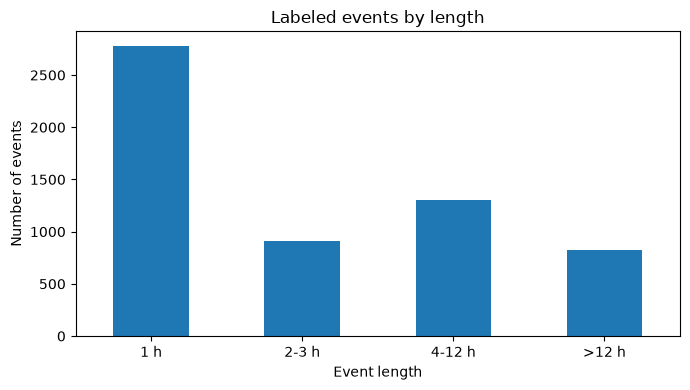

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
events["length_group"].value_counts().reindex(LENGTH_LABELS).plot(kind="bar", ax=ax)
ax.set_xlabel("Event length")
ax.set_ylabel("Number of events")
ax.set_title("Labeled events by length")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "lead_events_by_length.png", dpi=200)
plt.show()

## 8. Save the results

In [14]:
labels_out = g[["building_id", "timestamp", "label"] + label_cols + ["in_lead", "in_zero_run"]]
try:
    labels_out.to_parquet(OUT_DIR / "lead_labels.parquet", index=False)
    print("saved lead_labels.parquet")
except Exception as e:
    print("parquet not available (", type(e).__name__, "), saving csv.gz instead")
    labels_out.to_csv(OUT_DIR / "lead_labels.csv.gz", index=False)

pd.Series(sorted(labeled_buildings), name="building_id").to_csv(OUT_DIR / "labeled_building_ids.csv", index=False)
lab_meta.to_csv(OUT_DIR / "labeled_buildings_info.csv", index=False)
events.to_csv(OUT_DIR / "lead_events.csv", index=False)
n_all.to_csv(OUT_DIR / "table_events_all.csv")
h_all.to_csv(OUT_DIR / "table_hours_all.csv")
n_edu.to_csv(OUT_DIR / "table_events_education.csv")
h_edu.to_csv(OUT_DIR / "table_hours_education.csv")
n_use.to_csv(OUT_DIR / "table_events_usable.csv")
print("saved events and count tables to", OUT_DIR.resolve())

saved lead_labels.parquet
saved events and count tables to /Users/barnnitashrestha/DSAI/CP-LAB/Project/outputs


## 9. What to decide and write down

**What the real files showed (run on 18 October)**

- **LEAD file size.** The labeled file covers **200 buildings**: 1,749,494 rows, **37,296 labeled hours** (2.13% of rows) and **5,811 events** (5,716 usable after removing events mostly inside zero runs). The LEAD paper describes 1,413 labeled meters, and `test_features.csv` holds 206 other buildings with no labels. Check the authors' repository for fuller labels. Until then, say "200 labeled buildings" in the report.
- **How the labels were made.** By hand: annotators looked at plots in roughly 24-hour windows and marked point and sequence anomalies (LEAD 1.0 paper). So "agreement" means recovering what a person sees as unusual. It is not a confirmed fault.
- **The 200 labeled buildings.** 80 are Education, 62 Office, 23 Entertainment/public assembly, 13 Lodging/residential and 22 are of other types. They come from 14 of the 16 sites.
- **Events by length (all labeled buildings).** 2,780 of 1 h, 906 of 2-3 h, 1,302 of 4-12 h, 823 of over 12 h (longest 167 h). Every length group has at least 98 test events (at least 30 for Education only), so no group needs to be merged.
- **Readings did not match at first (90.4%), and this is explained.** (1) GEPIII stores site 0 in kBTU and LEAD in kWh (factor 0.2931). After converting, 98.96% of directly compared rows match. (2) 6.15% of LEAD rows have a blank reading where GEPIII has one; none of them is labeled anomalous. (3) 17,031 labeled hours have a LEAD reading of exactly 1.0 that GEPIII does not show; the reason is not known.
- **Consequences.** Use GEPIII readings for modeling and only the labels from LEAD. Use kWh everywhere, including site 0. Evaluate only on the labeled buildings. In the first run, which used all 1,413 GEPIII buildings, zero runs of 24 hours or more affected 3.89% of rows, and 2,222 labeled hours fell in them. This version counts them for the labeled buildings only, so the figures will differ.

**To write in the report**

- Unlabeled hours inside the labeled buildings are treated as normal. Buildings outside the labeled file are not used for evaluation.
- The zero-run length used and how many hours it affects.
- The rule for removing zero-run events (here: more than half the hours in a zero run).
- Education results are shown next to all-buildings results.
- LEAD 1.0 comes from the same source as GEPIII, so it is not an independent check.

To use the labels in your pipeline, merge `lead_labels` into your hourly table on `building_id` and `timestamp`, and restrict the evaluation to `labeled_building_ids.csv`.